# EV Perception: Object Detection Evaluation — RetinaNet

The same evaluation as Andrew's RF-DETR notebook (`EV_Perception_Demo.ipynb`), run on **RetinaNet**
(torchvision `retinanet_resnet50_fpn_v2`, COCO-pretrained), with per-image latency added.
The data, label loading, matching rules and metrics are his, so the numbers compare directly.

Precision = TP / (TP + FP). Recall = TP / (TP + FN).
A prediction counts as TP only when its class matches and IoU meets the threshold.
Each ground-truth box can match at most one prediction, processed in confidence order.
This demo reports fixed-threshold Precision/Recall, not mAP.

## Setup and sample download
Run all cells in order. Select your CUDA-enabled Python environment as the notebook kernel.
The install cell uses that kernel. Keep your working PyTorch installation (torch and torchvision).
Default: the first 500 labeled BDD100K test images. Change N for a larger sample.
The dataset is pinned to the version Andrew's run used (`REVISION`); the repo's newer layout has a
different label format.

In [1]:
%pip install huggingface_hub pillow matplotlib pyyaml pandas


[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
from huggingface_hub import HfFileSystem
REPO = "dronefreak/BDD100K"
# Pinned to the dataset version Andrew's RF-DETR run used. On 2026-10-13 the repo was restructured
# (raw JSON labels, no YOLO .txt labels or data.yaml), which load() below does not read.
REVISION = "2e47ffeefc1066a36ea8cefa324aae1dae0b5e33"
ROOT = f"datasets/{REPO}@{REVISION}"
fs = HfFileSystem()
print(fs.ls(ROOT, detail=False))
print(fs.ls(f"{ROOT}/" + fs.ls(ROOT, detail=False)[0].split("/")[-1], detail=False)[:10])

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


['datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data', 'datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/.gitattributes', 'datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/README.md', 'datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/bdd100k_banner.jpg']
['datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/images', 'datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/labels', 'datasets/dronefreak/BDD100K@2e47ffeefc1066a36ea8cefa324aae1dae0b5e33/data/data.yaml']


In [3]:
import os
from huggingface_hub import snapshot_download

SPLIT = "test"   # repository split name; require labels for evaluation
DATA_DIR = os.path.abspath("bdd_det")
N = 500   # first N labeled test images; raise for a bigger sample

all_files = [p.split(f"{ROOT}/")[1] for p in fs.glob(f"{ROOT}/**/*")]
imgs = sorted(p for p in all_files if f"/{SPLIT}/" in f"/{p}" and p.endswith(".jpg"))[:N]
labels = {os.path.splitext(os.path.basename(p))[0]: p
          for p in all_files if f"/{SPLIT}/" in f"/{p}" and p.endswith(".txt")}
lbls = [labels[os.path.splitext(os.path.basename(p))[0]] for p in imgs
        if os.path.splitext(os.path.basename(p))[0] in labels]
if not imgs:
    raise RuntimeError(f"No images found in split {SPLIT!r}.")
if len(lbls) != len(imgs):
    raise RuntimeError("Some images have no label file. Choose a labeled split; missing labels are not empty ground truth.")

yaml = [p for p in all_files if p.endswith((".yaml", ".yml"))]

print(len(imgs), "images |", len(lbls), "label files")
snapshot_download(REPO, repo_type="dataset", revision=REVISION, local_dir=DATA_DIR,
                  allow_patterns=imgs + lbls + yaml, max_workers=16)

500 images | 500 label files


Fetching 1001 files:   0%|          | 0/1001 [00:00<?, ?it/s]

Fetching 1001 files:  10%|█         | 103/1001 [00:00<00:00, 1024.89it/s]

Fetching 1001 files:  23%|██▎       | 228/1001 [00:00<00:00, 1155.27it/s]

Fetching 1001 files:  35%|███▍      | 350/1001 [00:00<00:00, 1181.73it/s]

Fetching 1001 files:  47%|████▋     | 469/1001 [00:00<00:00, 1172.01it/s]

... (2 outputs left out)

Fetching 1001 files:  84%|████████▍ | 839/1001 [00:00<00:00, 1206.67it/s]

Fetching 1001 files:  96%|█████████▋| 965/1001 [00:00<00:00, 1222.59it/s]

Fetching 1001 files: 100%|██████████| 1001/1001 [00:00<00:00, 1206.35it/s]

'/work/bdd_det'

In [4]:
from pathlib import Path
from PIL import Image

# Use only this run's selected files, not older cached images.
img_paths = [str(Path(DATA_DIR) / p) for p in imgs]
lbl_path = {Path(p).stem: str(Path(DATA_DIR) / p) for p in lbls}

def load(img_path):
    with Image.open(img_path) as source:
        img = source.convert("RGB")
    W, H = img.size
    label_file = lbl_path[Path(img_path).stem]
    boxes = []
    with open(label_file, encoding="utf-8") as f:
        for line in f:
            if not line.strip():
                continue
            c, cx, cy, w, h = map(float, line.split())
            if c != int(c) or w < 0 or h < 0:
                raise ValueError(f"Invalid YOLO label: {line}")
            boxes.append((int(c), [(cx-w/2)*W, (cy-h/2)*H,
                                   (cx+w/2)*W, (cy+h/2)*H]))
    return img, boxes

img, boxes = load(img_paths[0])
print(len(img_paths), "images", boxes[:3])

500 images [(9, [1000.69888, 281.99232, 1040.6272, 326.91168]), (9, [214.61311999999998, 172.19016, 274.5056, 229.58711999999997]), (9, [797.3152, 313.18596, 829.7568, 341.88444])]


{0: 'person', 1: 'rider', 2: 'car', 3: 'truck', 4: 'bus', 5: 'train', 6: 'motor', 7: 'bike', 8: 'traffic light', 9: 'traffic sign'}


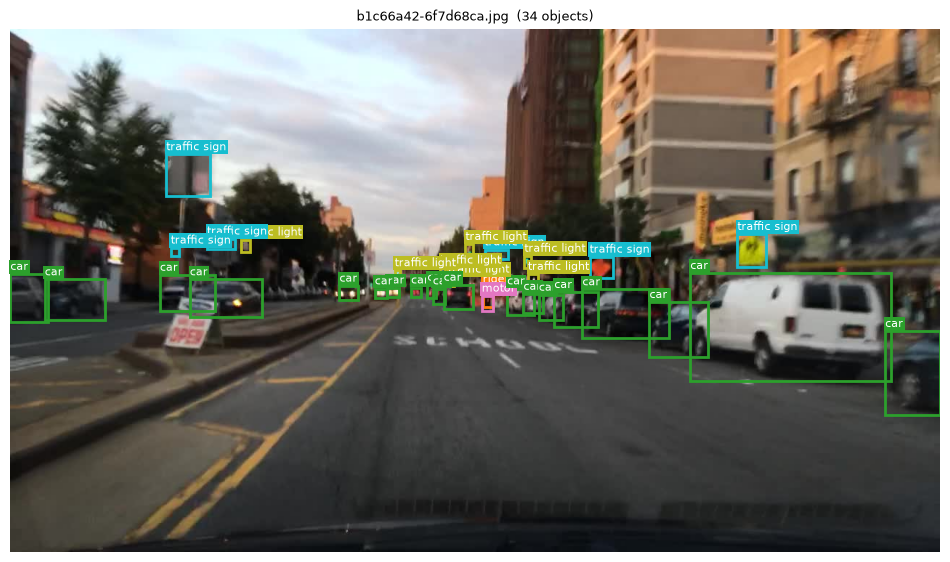

In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import glob, yaml

yaml_files = sorted(
    list(Path(DATA_DIR).rglob("*.yaml"))
    + list(Path(DATA_DIR).rglob("*.yml"))
)
yaml_file = str(yaml_files[0])
cfg = yaml.safe_load(open(yaml_file))

names = cfg["names"]
if isinstance(names, list):
    names = dict(enumerate(names))
names = {int(k): str(v) for k, v in names.items()}
print(names)

colors = plt.cm.tab10.colors

def show(img_path, ax=None):
    img, boxes = load(img_path)
    if ax is None:
        _, ax = plt.subplots(figsize=(12, 7))
    ax.imshow(img)
    for c, (x1, y1, x2, y2) in boxes:
        col = colors[c % len(colors)]
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                       fill=False, edgecolor=col, linewidth=2))
        ax.text(x1, y1 - 2, names[c], color="white", fontsize=8,
                va="bottom", bbox=dict(facecolor=col, edgecolor="none", pad=1))
    ax.set_title(f"{os.path.basename(img_path)}  ({len(boxes)} objects)", fontsize=9)
    ax.axis("off")

show(img_paths[0])

In [6]:
def calculate_IOU(box1, box2):
    x1, y1, x2, y2 = box1
    a1, b1, a2, b2 = box2
    intersection = max(0, min(x2, a2) - max(x1, a1)) * max(0, min(y2, b2) - max(y1, b1))
    area1 = max(0, x2-x1) * max(0, y2-y1)
    area2 = max(0, a2-a1) * max(0, b2-b1)
    union = area1 + area2 - intersection
    return intersection / union if union > 0 else 0.0


def match_boxes(gt, predictions, iou_threshold):
    # predictions: (dataset_class_id, xyxy_box, confidence)
    used = set()
    matches = []
    for cls, box, score in sorted(predictions, key=lambda p: p[2], reverse=True):
        candidates = [(calculate_IOU(box, gt_box), j)
                      for j, (gt_cls, gt_box) in enumerate(gt)
                      if gt_cls == cls and j not in used]
        best_iou, best_j = max(candidates, default=(0.0, -1))
        if best_j >= 0 and best_iou >= iou_threshold:
            used.add(best_j)
            matches.append((cls, best_iou))
    tp = len(matches)
    return tp, len(predictions)-tp, len(gt)-tp, matches

## Load RetinaNet and align classes
torchvision `retinanet_resnet50_fpn_v2` with its default COCO weights (downloaded on first run, 146 MB).
Images are passed as RGB tensors; resizing (shorter side 800) and normalizing happen inside the model.
COCO and BDD class IDs differ: resolve names before mapping to dataset IDs.
Only shared classes are evaluated; excluded BDD classes are printed.

**Latency** is timed per image from the decoded RGB image to the model's boxes (conversion to a
tensor, the network and its postprocessing). Reading the file from disk is not included. The first
`WARMUP_IMAGES` images are run once untimed first.

In [7]:
import os
import time
import numpy as np
import torch
import pandas as pd
from torchvision.models.detection import RetinaNet_ResNet50_FPN_V2_Weights, retinanet_resnet50_fpn_v2
from torchvision.transforms.functional import pil_to_tensor

CONF_THRESHOLD = 0.25          # same as Andrew's RF-DETR run
IOU_THRESHOLDS = [0.50, 0.85]
REQUIRE_ALL_CLASSES = False
WARMUP_IMAGES = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else f"CPU, {torch.get_num_threads()} threads")

weights = RetinaNet_ResNet50_FPN_V2_Weights.DEFAULT
COCO_CATEGORIES = weights.meta["categories"]   # index = model label id; "N/A" marks unused ids
# score_thresh filters inside the model, before NMS, like RF-DETR's threshold argument.
model = retinanet_resnet50_fpn_v2(weights=weights, score_thresh=CONF_THRESHOLD).eval().to(DEVICE)

ALIASES = {"pedestrian": "person", "bike": "bicycle", "motor": "motorcycle"}
def canonical(name):
    name = str(name).strip().lower().replace("_", " ")
    return ALIASES.get(name, name)

dataset_ids = {canonical(name): cls for cls, name in names.items()}
model_class_names = [n for n in COCO_CATEGORIES if n not in ("N/A", "__background__")]
evaluated_classes = {dataset_ids[canonical(name)] for name in model_class_names
                     if canonical(name) in dataset_ids}
excluded = [names[cls] for cls in names if cls not in evaluated_classes]
print("Evaluated classes:", [names[cls] for cls in sorted(evaluated_classes)])
print("Excluded dataset classes:", excluded)
if not evaluated_classes:
    raise ValueError("No shared classes; check dataset names and ALIASES.")
if REQUIRE_ALL_CLASSES and excluded:
    raise ValueError("Pretrained model does not support all dataset classes.")

def sync():
    # GPU calls return before the work finishes; wait so the timing is real.
    if DEVICE == "cuda":
        torch.cuda.synchronize()

def retinanet_detect(img_rgb):
    """RGB PIL image -> list of (class_name, xyxy, confidence)."""
    x = pil_to_tensor(img_rgb).to(DEVICE).float().div_(255.0)
    with torch.inference_mode():
        out = model([x])[0]
    return [(COCO_CATEGORIES[int(c)], b, float(s)) for b, s, c in
            zip(out["boxes"].cpu().tolist(), out["scores"].cpu().tolist(), out["labels"].cpu().tolist())]

LATENCY_MS = []

def predict_boxes(img_path):
    with Image.open(img_path) as source:
        img_rgb = source.convert("RGB")
    sync()
    start = time.perf_counter()
    rows = retinanet_detect(img_rgb)
    sync()
    LATENCY_MS.append((time.perf_counter() - start) * 1000)
    predictions = []
    for class_name, box, conf in rows:
        dataset_cls = dataset_ids.get(canonical(class_name))
        if dataset_cls is not None:
            predictions.append((dataset_cls, [float(v) for v in box], float(conf)))
    return predictions

Device: CPU, 10 threads


Evaluated classes: ['person', 'car', 'truck', 'bus', 'train', 'motor', 'bike', 'traffic light']
Excluded dataset classes: ['rider', 'traffic sign']


## Evaluate
Inference runs once per image. The same predictions are evaluated at both IoU thresholds.
Mean matched IoU includes TP matches only; it is undefined when there are no matches.

In [8]:
def evaluate_model(predict_fn, paths, class_ids, thresholds=(0.5, 0.85), progress_every=50):
    records = []
    details = []
    for i, path in enumerate(paths):
        _, gt_all = load(path)
        unknown = {cls for cls, box in gt_all} - set(names)
        if unknown:
            raise ValueError(f"Label class IDs missing from YAML: {unknown}")
        gt = [(cls, box) for cls, box in gt_all if cls in class_ids]
        pred = [(cls, box, conf) for cls, box, conf in predict_fn(path) if cls in class_ids]
        details.append(dict(path=path, gt=gt, predictions=pred))
        for threshold in thresholds:
            tp, fp, fn, matches = match_boxes(gt, pred, threshold)
            records.append(dict(image=Path(path).name, iou_threshold=threshold,
                                TP=tp, FP=fp, FN=fn,
                                matched_iou_sum=sum(iou for _, iou in matches)))
        if (i + 1) % progress_every == 0 or i + 1 == len(paths):
            print(f"{i+1}/{len(paths)}: {Path(path).name}")
    if not records:
        raise ValueError("No images to evaluate.")
    per_image = pd.DataFrame(records)
    totals = per_image.groupby("iou_threshold")[["TP", "FP", "FN", "matched_iou_sum"]].sum()
    totals["Precision"] = totals.TP / (totals.TP + totals.FP).replace(0, float("nan"))
    totals["Recall"] = totals.TP / (totals.TP + totals.FN).replace(0, float("nan"))
    totals["Mean matched IoU"] = totals.matched_iou_sum / totals.TP.replace(0, float("nan"))
    return totals.drop(columns="matched_iou_sum"), per_image, details

# Warm-up: the first calls are slower (memory allocation, kernel selection); they are not timed.
for path in img_paths[:WARMUP_IMAGES]:
    with Image.open(path) as source:
        retinanet_detect(source.convert("RGB"))
LATENCY_MS.clear()

summary, per_image, details = evaluate_model(predict_boxes, img_paths,
                                            evaluated_classes, IOU_THRESHOLDS)
display(summary.round(4))
display(per_image.drop(columns="matched_iou_sum"))

50/500: b1d9e136-9ab25cb3.jpg


100/500: b1f85377-44885085.jpg


150/500: b216243d-ad4306b9.jpg


200/500: b24380ab-6dbeb908.jpg


250/500: b258a38b-0126cc8c.jpg


300/500: b26f8762-61cfb033.jpg


... (2 outputs left out)

450/500: b2d502aa-f0b28e3e.jpg


500/500: b2f4a409-80dacf25.jpg


,TP,FP,FN,Precision,Recall,Mean matched IoU
iou_threshold,,,,,,
0.50,4434,6741,3112,0.3968,0.5876,0.7607
0.85,1429,9746,6117,0.1279,0.1894,0.9097


,image,iou_threshold,TP,FP,FN
0,b1c66a42-6f7d68ca.jpg,0.50,18,22,9
1,b1c66a42-6f7d68ca.jpg,0.85,6,34,21
2,b1c81faa-3df17267.jpg,0.50,1,8,2
3,b1c81faa-3df17267.jpg,0.85,0,9,3
4,b1c81faa-c80764c5.jpg,0.50,2,7,9
...,...,...,...,...,...
995,b2f4a409-5adcc4f0.jpg,0.85,6,25,5
996,b2f4a409-5ddff11a.jpg,0.50,1,6,2
997,b2f4a409-5ddff11a.jpg,0.85,1,6,2
998,b2f4a409-80dacf25.jpg,0.50,5,23,4


,Images timed,Mean (ms),Median (ms),p95 (ms),p99 (ms),Min (ms),Max (ms),Images per second
RetinaNet on cpu,500,2086.8,2034.4,2682.2,3081.0,1472.1,3331.5,0.5


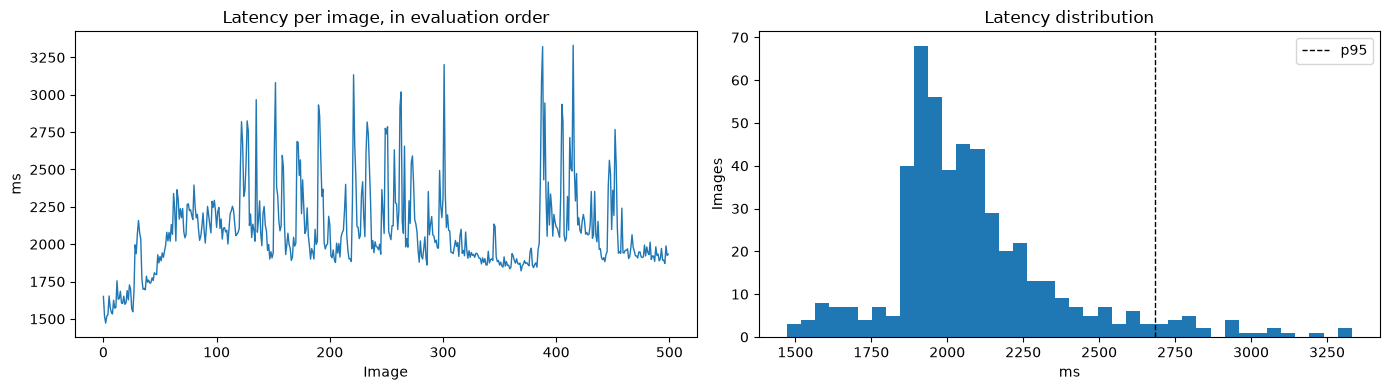

In [9]:
lat = np.asarray(LATENCY_MS)
latency = pd.DataFrame([{
    "Images timed": len(lat),
    "Mean (ms)": lat.mean(), "Median (ms)": np.percentile(lat, 50),
    "p95 (ms)": np.percentile(lat, 95), "p99 (ms)": np.percentile(lat, 99),
    "Min (ms)": lat.min(), "Max (ms)": lat.max(),
    "Images per second": 1000 / lat.mean(),
}], index=[f"RetinaNet on {DEVICE}"])
display(latency.round(1))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))
ax1.plot(lat, linewidth=1)
ax1.set_xlabel("Image")
ax1.set_ylabel("ms")
ax1.set_title("Latency per image, in evaluation order")
ax2.hist(lat, bins=40)
ax2.axvline(np.percentile(lat, 95), color="k", linestyle="--", linewidth=1, label="p95")
ax2.set_xlabel("ms")
ax2.set_ylabel("Images")
ax2.set_title("Latency distribution")
ax2.legend()
plt.tight_layout()
plt.show()

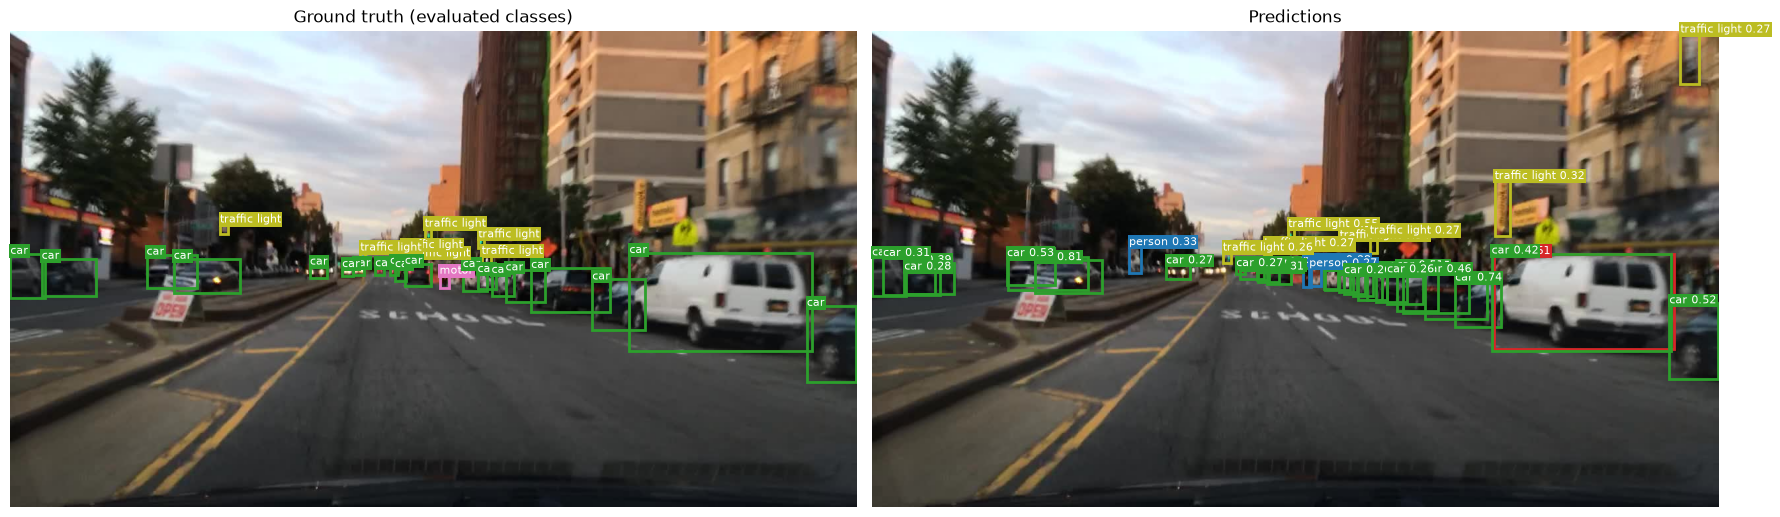

In [10]:
def show_comparison(item):
    img, _ = load(item["path"])
    fig, axes = plt.subplots(1, 2, figsize=(18, 6))
    for ax, title, entries in zip(axes, ["Ground truth (evaluated classes)", "Predictions"],
                                  [item["gt"], item["predictions"]]):
        ax.imshow(img)
        for entry in entries:
            cls, (x1, y1, x2, y2) = entry[:2]
            col = colors[cls % len(colors)]
            ax.add_patch(patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                           fill=False, edgecolor=col, linewidth=2))
            label = names[cls] + (f" {entry[2]:.2f}" if len(entry) == 3 else "")
            ax.text(x1, y1, label, color="white", fontsize=8,
                    bbox=dict(facecolor=col, edgecolor="none", pad=1))
        ax.set_title(title)
        ax.axis("off")
    plt.tight_layout()
    plt.show()

show_comparison(details[0])

In [11]:
rows = []

for threshold in IOU_THRESHOLDS:
    for cls in sorted(evaluated_classes):
        tp = fp = fn = 0
        matched_ious = []

        for item in details:
            gt = [box for box in item["gt"] if box[0] == cls]
            pred = [box for box in item["predictions"] if box[0] == cls]

            t, f, n, matches = match_boxes(gt, pred, threshold)
            tp += t
            fp += f
            fn += n
            matched_ious.extend(iou for _, iou in matches)

        rows.append({
            "IoU threshold": threshold,
            "Class": names[cls],
            "TP": tp,
            "FP": fp,
            "FN": fn,
            "Precision": tp / (tp + fp) if tp + fp else float("nan"),
            "Recall": tp / (tp + fn) if tp + fn else float("nan"),
            "Mean matched IoU": (
                sum(matched_ious) / len(matched_ious)
                if matched_ious else float("nan")
            ),
        })

per_class = pd.DataFrame(rows)
display(per_class.round(4))

,IoU threshold,Class,TP,FP,FN,Precision,Recall,Mean matched IoU
0,0.50,person,449,704,297,0.3894,0.6019,0.7459
1,0.50,car,3215,3587,1847,0.4727,0.6351,0.7765
2,0.50,truck,121,535,91,0.1845,0.5708,0.8224
3,0.50,bus,38,80,53,0.3220,0.4176,0.8696
4,0.50,train,0,16,1,0.0000,0.0000,NaN
5,0.50,motor,11,65,9,0.1447,0.5500,0.7019
6,0.50,bike,15,24,25,0.3846,0.3750,0.7369
7,0.50,traffic light,585,1730,789,0.2527,0.4258,0.6675
8,0.85,person,89,1064,657,0.0772,0.1193,0.8973
9,0.85,car,1209,5593,3853,0.1777,0.2388,0.9105


In [12]:
from datetime import datetime

out_dir = Path("results") / datetime.now().strftime("retinanet_eval_%Y%m%d_%H%M%S")
out_dir.mkdir(parents=True, exist_ok=True)
summary.to_csv(out_dir / "summary.csv")
per_class.to_csv(out_dir / "per_class.csv", index=False)
latency.to_csv(out_dir / "latency.csv")
pd.DataFrame({"image": [Path(p).name for p in img_paths], "latency_ms": LATENCY_MS}
             ).to_csv(out_dir / "latency_per_image.csv", index=False)
print("Saved to", out_dir.resolve())

Saved to /work/results/retinanet_eval_20261017_201028


## Notes
- Settings match Andrew's RF-DETR run: same dataset version, confidence threshold 0.25, IoU 0.50 and 0.85,
  same matching. Use the same `N` as the run you compare against.
- Latency depends on the hardware: compare models on the same machine. RetinaNet is a large model
  (ResNet-50 backbone, 800-pixel input) and is much faster on a GPU than on a CPU.
- BDD's `rider` and `traffic sign` have no COCO class and are not scored. A rider that RetinaNet calls
  `person` counts as a false positive, which lowers person precision (as it does for RF-DETR).
- BDD labels vans as `car`; RetinaNet often calls them `truck`, which counts as one false positive and
  one false negative. This is why truck precision is low.